In [13]:
%pip install -q -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 kB 4.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [14]:
import json
import os
import shutil
import subprocess
from pathlib import Path

# Must be set before CUDA is initialised; reduces fragmentation-related OOMs
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import cv2
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image
from pycocotools import mask as mask_utils

from sklearn.model_selection import train_test_split
print("CUDA available:", torch.cuda.is_available())

from ultralytics import YOLO

CUDA available: True
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [15]:
COMPETITION = "filament-segmentation-2026"
DATA_DIR = Path(f"/kaggle/input/competitions/{COMPETITION}/MAGFiLO_1.0_Kaggle_2026")
WORK_DIR = Path("/kaggle/working")  # /kaggle/input is read-only

TRAIN_IMAGES_DIR = DATA_DIR / "train" / "train_images"
ANNOTATIONS_FILE = DATA_DIR / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TEST_IMAGES_DIR = DATA_DIR / "test" / "test_images"

MODEL_NAME = "yolo26s-seg.pt"
IMGSZ = 1280  # shared by training and prediction
VAL_FRACTION = 0.2
SEED = 42

In [16]:
with open(ANNOTATIONS_FILE) as f:
    coco = json.load(f)

# Rename "id" to avoid a clash with the annotation "id" column
images_df = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
annotations_df = pd.DataFrame(coco["annotations"])
df = annotations_df.merge(images_df, on="image_id", how="left", suffixes=("", "_image"))
df.head()

,segmentation,area,iscrowd,spine,image_id,bbox,category_id,id,license,file_name,url,height,width,date_captured
0,"[[480.9382, 850.955, 480.307, 852.0535, 478.29...",750.0,0,"[388.7268, 805.455, 394.4037, 809.9707, 396.72...",040301-20140609195854Bh,"[388.4121, 799.966, 92.52639999999997, 52.4850...",2,d7fd9cdb-3f34-4dfc-a1fa-c1fd25110a98,1,20140609195854Bh.jpeg,https://gong2.nso.edu/HA/hag/201406/20140609/2...,2048,2048,2014-06-09 19:58:54
1,"[[523.9768, 1330.1999, 522.4368, 1327.5199, 51...",1060.0,0,"[433.2831, 1310.7166, 448.6422, 1328.9199, 459...",040301-20140609195854Bh,"[427.3645, 1310.312, 96.6123, 46.15890000000013]",3,ca65251f-f7c8-4553-ad55-ad0f06272782,1,20140609195854Bh.jpeg,https://gong2.nso.edu/HA/hag/201406/20140609/2...,2048,2048,2014-06-09 19:58:54
2,"[[782.6395, 633.6624, 779.1879, 630.2108, 775....",1381.0,0,"[778.8281, 719.511, 767.5568, 713.9816, 765.23...",040301-20140609195854Bh,"[753.6963, 576.3292, 28.943200000000047, 145.3...",1,7b301b5d-fe5d-4b4d-b0b7-41b0f8cabeec,1,20140609195854Bh.jpeg,https://gong2.nso.edu/HA/hag/201406/20140609/2...,2048,2048,2014-06-09 19:58:54
3,"[[1593.8485, 699.2871, 1591.2593, 706.694, 159...",719.0,0,"[1573.8616, 655.3172, 1571.2071, 660.4296, 157...",040301-20140609195854Bh,"[1567.404, 654.9481, 26.704500000000053, 96.05...",2,184911bf-d671-4a08-bc84-6f5fb7ce5277,1,20140609195854Bh.jpeg,https://gong2.nso.edu/HA/hag/201406/20140609/2...,2048,2048,2014-06-09 19:58:54
4,"[[1579.903, 626.9136, 1576.9871, 617.0664, 156...",289.0,0,"[1577.9188, 629.7081, 1570.4419, 614.3269, 156...",040301-20140609195854Bh,"[1558.4171, 589.3484, 21.48590000000013, 40.87...",3,67dcd25e-ed1e-4565-960e-d653c9a905ab,1,20140609195854Bh.jpeg,https://gong2.nso.edu/HA/hag/201406/20140609/2...,2048,2048,2014-06-09 19:58:54


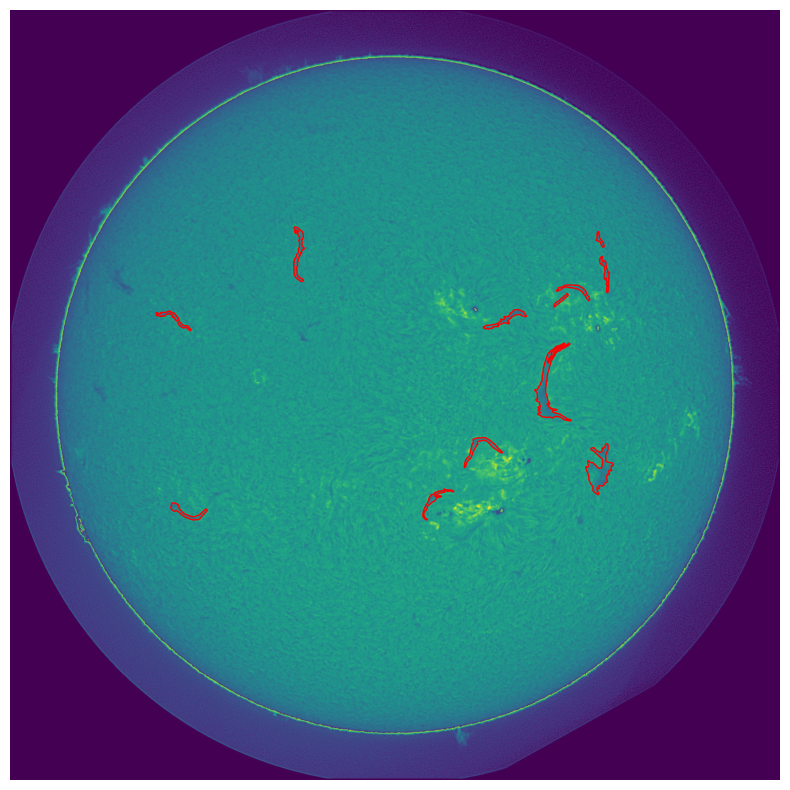

In [17]:
def show_annotations(df, file_name):
    """Overlay all annotated polygons on one training image."""
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(Image.open(TRAIN_IMAGES_DIR / file_name))
    for segmentation in df.loc[df["file_name"] == file_name, "segmentation"]:
        points = np.array(segmentation[0]).reshape(-1, 2)
        ax.add_patch(patches.Polygon(points, closed=True, linewidth=1, edgecolor="r", facecolor="none"))
    ax.axis("off")
    plt.show()


show_annotations(df, df["file_name"].iloc[0])

In [18]:
def normalize_polygon(points, width, height):
    """Flat [x1, y1, x2, y2, ...] pixel coordinates -> 0-1 range, as YOLO expects."""
    coords = np.array(points, dtype=float).reshape(-1, 2) / [width, height]
    return coords.ravel().tolist()


df["yolo_polygon"] = df.apply(
    lambda row: normalize_polygon(row["segmentation"][0], row["width"], row["height"]),
    axis=1,
)

# Split by image so annotations of one image never land in both sets
train_files, val_files = train_test_split(
    df["file_name"].unique(), test_size=VAL_FRACTION, random_state=SEED
)
df_train = df[df["file_name"].isin(train_files)]
df_val = df[df["file_name"].isin(val_files)]

for name, part in [("Train", df_train), ("Validation", df_val)]:
    print(f"{name}: {part['file_name'].nunique()} images, {len(part)} annotations")

Train: 565 images, 6647 annotations
Validation: 142 images, 1552 annotations


In [19]:
def write_split(df_split, split):
    """Copy images and write YOLO label files to WORK_DIR/{images,labels}/<split>."""
    images_out = WORK_DIR / "images" / split
    labels_out = WORK_DIR / "labels" / split
    for folder in (images_out, labels_out):
        shutil.rmtree(folder, ignore_errors=True)
        folder.mkdir(parents=True)

    for file_name, group in df_split.groupby("file_name"):
        shutil.copy(TRAIN_IMAGES_DIR / file_name, images_out / file_name)
        lines = [f"0 {' '.join(map(str, polygon))}" for polygon in group["yolo_polygon"]]
        (labels_out / f"{Path(file_name).stem}.txt").write_text("\n".join(lines) + "\n")

    print(f"{split}: {len(list(images_out.iterdir()))} images, {len(list(labels_out.iterdir()))} labels")


write_split(df_train, "train")
write_split(df_val, "val")

train: 565 images, 565 labels
val: 142 images, 142 labels


In [20]:
DATA_YAML = WORK_DIR / "data.yaml"
DATA_YAML.write_text(
    yaml.safe_dump(
        {
            "path": str(WORK_DIR),
            "train": "images/train",
            "val": "images/val",
            "names": {0: "filament"},
        },
        sort_keys=False,
    )
)

79

In [21]:
# Previous best: imgsz=1024, scale=0.7, copy_paste=0.3, flips=0.5, AdamW lr0=0.001 lrf=0.005, no degrees/mask_ratio/hsv
TRAIN_ARGS = dict(
    data=str(DATA_YAML),
    epochs=150,
    imgsz=IMGSZ,
    batch=4,  # fixed: auto batch (-1) underestimates mask memory at this imgsz
    patience=30,  # early stopping
    device=0,
    mask_ratio=2,  # mask memory grows with 1/mask_ratio^2; 1 was too heavy at imgsz=1280
    # https://docs.ultralytics.com/guides/yolo-data-augmentation
    scale=0.3,
    hsv_h=0,
    hsv_s=0,
    degrees=13,
    copy_paste=0.3,
    fliplr=0.5,
    flipud=0.5,
    optimizer="AdamW",  # lr0 is ignored with optimizer="auto"
    lr0=0.001,
    lrf=0.005,
)

model = YOLO(MODEL_NAME)
model.train(**TRAIN_ARGS)
RUN_DIR = Path(model.trainer.save_dir)

Ultralytics 8.4.187 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=13, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.005, mask_ratio=2, max_det=300, mixup=0.0, mode=train, model=yolo26s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/150      10.8G      1.517      2.588      2.006   0.003676      1.531        132       1280: 4% ╸─────────── 6/142 1.1s/it 6.3s<2:24


KeyboardInterrupt: 

In [ ]:
def show_images(paths, titles=None, figsize=(20, 12)):
    """Show saved images side by side at high quality."""
    fig, axes = plt.subplots(1, len(paths), figsize=figsize, dpi=180, squeeze=False)
    for ax, path, title in zip(axes[0], paths, titles or [""] * len(paths)):
        ax.imshow(plt.imread(path), interpolation="lanczos")
        ax.set_title(title, fontsize=18)
        ax.axis("off")
    fig.tight_layout(pad=0.5)
    plt.show()


show_images([RUN_DIR / "results.png"])
show_images([RUN_DIR / "confusion_matrix.png"])
show_images(
    [RUN_DIR / "val_batch0_labels.jpg", RUN_DIR / "val_batch0_pred.jpg"],
    titles=["Validation labels", "Validation predictions"],
    figsize=(30, 14),
)

In [ ]:
model = YOLO(str(RUN_DIR / "weights" / "best.pt"))
test_results = model.predict(
    source=str(TEST_IMAGES_DIR),
    imgsz=IMGSZ,
    conf=0.1,
    retina_masks=True,  # masks at original image resolution
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(WORK_DIR),
    name="test_predictions",
    exist_ok=True,
)

In [ ]:
def result_to_rows(result):
    """One RLE row per filament; higher-confidence instances claim overlapping pixels first."""
    if result.masks is None:
        return []

    image_stem = Path(result.path).stem
    h, w = result.orig_shape
    occupied = np.zeros((h, w), dtype=bool)
    rows = []

    for i in result.boxes.conf.argsort(descending=True).cpu().numpy():
        polygon = np.round(result.masks.xy[i]).astype(np.int32)
        if len(polygon) < 3:
            continue

        canvas = np.zeros((h, w), dtype=np.uint8)
        cv2.fillPoly(canvas, [polygon], 1)
        mask = canvas.astype(bool) & ~occupied
        if not mask.any():
            continue

        occupied |= mask
        rle = mask_utils.encode(np.asfortranarray(mask.astype(np.uint8)))
        rows.append({
            "filament_id": f"{image_stem}_{len(rows) + 1}",
            "segmentation_rle": rle["counts"].decode("utf-8"),
        })
    return rows


submission = pd.DataFrame(
    [row for result in test_results for row in result_to_rows(result)],
    columns=["filament_id", "segmentation_rle"],
)
submission.head()

In [ ]:
SUBMISSION_CSV = WORK_DIR / "submission.csv"
submission.to_csv(SUBMISSION_CSV, index=False)

# The settings in the message make each score traceable to its run
MESSAGE = (
    f"{MODEL_NAME} imgsz={IMGSZ} epochs={TRAIN_ARGS['epochs']} "
    f"scale={TRAIN_ARGS['scale']} degrees={TRAIN_ARGS['degrees']}"
)

subprocess.run(
    ["kaggle", "competitions", "submit", "-c", COMPETITION, "-f", str(SUBMISSION_CSV), "-m", MESSAGE],
    check=True,
)